In [1]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
import json
import pandas as pd
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import numpy as np

# Data Loading miRMA

In [3]:
fuzz_res_dir = Path(r"C:\Users\jonas\OneDrive\Desktop\Semester_4_Bio\Masterpraktikum\Data\fuzzy_res_miRNA")

In [4]:
with open(r"C:\Users\jonas\OneDrive\Desktop\Semester_4_Bio\Masterpraktikum\relevant_views_miRNA.json", "r") as f:
    data = json.load(f)

In [5]:
cond_matches = pd.read_csv(r"C:\\Users\\jonas\\OneDrive\\Desktop\\Semester_4_Bio\\Masterpraktikum\\condition_matches_miRNA.csv", index_col=0)
add_cond_matches = pd.DataFrame([["GSE205119_GSE137580", "hsa_circ_0002457", "WT", "hsa_circ_0002457", "WT", "KO", "hsa_circ_0002457_-WT"], ["GSE205119_GSE137580", "hsa_circ_0122319", "WT", "hsa_circ_0122319", "WT", "KO", "hsa_circ_0122319-WT"]], columns=cond_matches.columns)
cond_matches = pd.concat([cond_matches, add_cond_matches])
cond_matches.head()

,accession,test,reference,test_coef,reference_coef,groupcol,safe_label
1,GSE137582,LDLR(W483STOP)+/+,WT,LDLR.W483STOP....,WT,KO,LDLR.W483STOP...._-_WT
2,GSE137580,oxLDL,Ctrl,oxLDL,Ctrl,medication,oxLDL_-_Ctrl
3,GSE205119,hsa_circ_0002457,hsa_circ_0122319,hsa_circ_0002457,hsa_circ_0122319,KO,hsa_circ_0002457_-_hsa_circ_0122319
4,GSE205119_GSE137580,hsa_circ_0122319,WT,hsa_circ_0122319,WT,KO,hsa_circ_0122319_-_WT
5,GSE205119_GSE137580,hsa_circ_0002457,WT,hsa_circ_0002457,WT,KO,hsa_circ_0002457_-_WT


In [6]:
meta = pd.read_excel(r"C:\Users\jonas\OneDrive\Desktop\Semester_4_Bio\Masterpraktikum\metadata_all_samples_new.xlsx")
meta = meta[~meta['sample_nr'].isna()]
meta["sample_nr"] = meta['sample_nr'].astype(int)
meta.head()

,accession,chip,species,sample,cell_type,location,sex,age,diet,medication,...,dose,duration,Hutchinson-Gilford,diabetis,CAD,CVD,symptomatic_atherosclerosis,combined_condition,sample_nr,Original Name
0,GSE152884,Affymetrix Mouse Transcriptome Array 1.0,Mouse,GSM4629022,ECs,thoratic aorta,NaN,NaN,chow,Ctrl,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ECs|thoratic aorta|||chow|Ctrl|WT|||||||,13,NaN
1,GSE152884,Affymetrix Mouse Transcriptome Array 1.0,Mouse,GSM4629023,ECs,thoratic aorta,NaN,NaN,chow,Ctrl,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ECs|thoratic aorta|||chow|Ctrl|WT|||||||,14,NaN
2,GSE152884,Affymetrix Mouse Transcriptome Array 1.0,Mouse,GSM4629024,ECs,thoratic aorta,NaN,NaN,chow,Ctrl,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ECs|thoratic aorta|||chow|Ctrl|WT|||||||,15,NaN
3,GSE152884,Affymetrix Mouse Transcriptome Array 1.0,Mouse,GSM4629025,ECs,thoratic aorta,NaN,NaN,chow,Ctrl,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ECs|thoratic aorta|||chow|Ctrl|WT|||||||,16,NaN
4,GSE152884,Affymetrix Mouse Transcriptome Array 1.0,Mouse,GSM4629026,ECs,thoratic aorta,NaN,NaN,chow,Ctrl,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"ECs|thoratic aorta|||chow|Ctrl|Mef2a, Mef2c, M...",17,NaN


human_mRNA = [
    "GSE20060", "GSE72633", "GSE20739", "GSE28117", "GSE49670", "GSE72180", "GSE111782", "GSE137578", "GSE205120"
]
human_miRNA = [
    "GSE59421", "GSE111794", "GSE137580", "GSE168149", "GSE205119"
]
mouse_mRNA = [
    "GSE42419", "GSE137581", "GSE48006"
]
mouse_miRNA = [
    "GSE99188", "GSE137582", "GSE89858"
]

# Process data into useful combinations

In [7]:
miRNA_data = pd.DataFrame(data).T
miRNA_data['n_overlap'] = [len(x) for x in miRNA_data['Overlap']]

accession = []
contrast = []
for x in miRNA_data.index:
    accession_parts = []
    j = 0
    for i, y in enumerate(x.split("_")):
        if not y.startswith("GSE"):
            j=i
            break
    accession.append("_".join(x.split("_")[:j]))
    contrast.append("_".join(x.split("_")[j:-1]))
miRNA_data['accession'] = accession
miRNA_data['contrast'] = contrast
miRNA_data_comb = miRNA_data.merge(cond_matches, left_on=["accession", "contrast"], right_on=["accession", "safe_label"])
miRNA_data_comb.index = miRNA_data_comb["accession"] + "_" + miRNA_data_comb["safe_label"]
miRNA_data_comb.head()

,padj,logfc,Overlap,n_overlap,accession,contrast,test,reference,test_coef,reference_coef,groupcol,safe_label
GSE137582_LDLR.W483STOP...._-_WT,"[mmu-let-7e-3p, mmu-miR-714, mmu-miR-143-5p, m...","[mmu-let-7e-3p, mmu-miR-714, mmu-miR-143-5p, m...","[mmu-miR-139-5p, mmu-miR-3960, mmu-miR-133a-3p...",41,GSE137582,LDLR.W483STOP...._-_WT,LDLR(W483STOP)+/+,WT,LDLR.W483STOP....,WT,KO,LDLR.W483STOP...._-_WT
GSE137580_oxLDL_-_Ctrl,"[hsa-miR-4697-5p, hsa-miR-937-5p, hsa-miR-370-...","[hsa-miR-4697-5p, hsa-miR-937-5p, hsa-miR-370-...","[hsa-miR-4697-5p, hsa-miR-7150, hsa-miR-5703, ...",21,GSE137580,oxLDL_-_Ctrl,oxLDL,Ctrl,oxLDL,Ctrl,medication,oxLDL_-_Ctrl
GSE205119_hsa_circ_0002457_-_hsa_circ_0122319,"[hsa-miR-8069, hsa-miR-1260b, hsa-miR-8072, hs...","[hsa-miR-8069, hsa-miR-1260b, hsa-miR-8072, hs...","[hsa-miR-1260b, hsa-miR-767-3p, hsa-miR-8069, ...",4,GSE205119,hsa_circ_0002457_-_hsa_circ_0122319,hsa_circ_0002457,hsa_circ_0122319,hsa_circ_0002457,hsa_circ_0122319,KO,hsa_circ_0002457_-_hsa_circ_0122319
GSE205119_GSE137580_hsa_circ_0122319_-_WT,"[hsa-miR-6131, hsa-miR-4442, hsa-miR-1229-5p, ...","[hsa-miR-6131, hsa-miR-4442, hsa-miR-1229-5p, ...","[hsa-miR-1207-5p, hsa-miR-362-3p, hsa-miR-6131...",353,GSE205119_GSE137580,hsa_circ_0122319_-_WT,hsa_circ_0122319,WT,hsa_circ_0122319,WT,KO,hsa_circ_0122319_-_WT
GSE205119_GSE137580_hsa_circ_0002457_-_WT,"[hsa-miR-6131, hsa-miR-4442, hsa-miR-1229-5p, ...","[hsa-miR-6131, hsa-miR-4442, hsa-miR-1229-5p, ...","[hsa-miR-1207-5p, hsa-miR-362-3p, hsa-miR-6131...",344,GSE205119_GSE137580,hsa_circ_0002457_-_WT,hsa_circ_0002457,WT,hsa_circ_0002457,WT,KO,hsa_circ_0002457_-_WT


# test data loading for expression validation

In [8]:
def check_expression(metadata, gse, condition, target_genes, condition_col=True):
    meta_sub = metadata[(metadata['accession'] == gse) & (metadata[condition_col]==condition)]
    datasets = pd.DataFrame()
    for file in (fuzz_res_dir / f"{gse}_norm_data_E_sample" / "fuzzy_values").glob("*"):
        if any([str(x) in file.name for x in meta_sub['sample']]):
            tmp = pd.read_csv(file, sep="\t", index_col=0)
            tmp = tmp.loc[target_genes, :]
            datasets = pd.concat([datasets, tmp])
    maxes = datasets[["0", "LOW", "low", "mid", "high", "HIGH"]].max(axis=1)
    datasets_bool = datasets[["0", "LOW", "low", "mid", "high", "HIGH"]].copy()
    for col in datasets_bool.columns:
        datasets_bool[col] = (datasets_bool[col] == maxes)
    return datasets_bool.groupby(level=0).sum()

In [9]:
results = {}
human_miRNA_ds_counter = {"ECs": Counter(), "SMCs": Counter(), "plaque": Counter(), "tissue": Counter()}
mouse_miRNA_ds_counter = {"ECs": Counter(), "SMCs": Counter(), "plaque": Counter(), "tissue": Counter()}
human_miRNA_ds = {"ECs": defaultdict(list), "SMCs": defaultdict(list), "plaque": defaultdict(list), "tissue": defaultdict(list)}
mouse_miRNA_ds = {"ECs": defaultdict(list), "SMCs": defaultdict(list), "plaque": defaultdict(list), "tissue": defaultdict(list)}
human_miRNA_ds_ext = {"ECs": defaultdict(list), "SMCs": defaultdict(list), "plaque": defaultdict(list), "tissue": defaultdict(list)}
mouse_miRNA_ds_ext = {"ECs": defaultdict(list), "SMCs": defaultdict(list), "plaque": defaultdict(list), "tissue": defaultdict(list)}
for i, row in miRNA_data_comb.iterrows():
    targets = row["Overlap"]
    clean_targets = [x for x in targets if not x.startswith("A_")]
    test_df = check_expression(metadata = meta, gse = row['accession'], condition = row['test'], target_genes = clean_targets, condition_col=row['groupcol'])
    ref_df = check_expression(metadata = meta, gse = row['accession'], condition = row['reference'], target_genes = clean_targets, condition_col = row['groupcol'])
    
    threshold_test = np.ceil(test_df.sum(axis=1)[0])
    threshold_ref = np.ceil(ref_df.sum(axis=1)[0])

    test_bool = test_df[["mid", "high", "HIGH"]].sum(axis=1) >= threshold_test
    ref_bool = ref_df[["mid", "high", "HIGH"]].sum(axis=1) >= threshold_ref

    results[i] = {
        "test": test_df[test_bool | ref_bool],
        "ref": ref_df[ref_bool | test_bool]
        }
    print(f"{row['accession']}, {row['test']}-{row['reference']}: {sum(test_bool | ref_bool)}")
    celltype = meta.loc[meta['accession']==row['accession'], 'cell_type'].iloc[0]
    print(celltype)
    for miRNA in clean_targets:
        if test_bool[miRNA] or ref_bool[miRNA]:
            if meta.loc[meta['accession']==row['accession'], 'species'].iloc[0] == "Human":
                human_miRNA_ds_ext[celltype][miRNA].append((row['accession'], row['safe_label']))
                human_miRNA_ds[celltype][miRNA].append(row['accession'])
                human_miRNA_ds_counter[celltype].update([miRNA])
            else:
                mouse_miRNA_ds_ext[celltype][miRNA].append((row['accession'], row['safe_label']))
                mouse_miRNA_ds[celltype][miRNA].append(row['accession'])
                mouse_miRNA_ds_counter[celltype].update([miRNA])
human_miRNA_ds_ext

GSE137582, LDLR(W483STOP)+/+-WT: 34
tissue
GSE137580, oxLDL-Ctrl: 7
ECs
GSE205119, hsa_circ_0002457-hsa_circ_0122319: 3
ECs
GSE205119_GSE137580, hsa_circ_0122319-WT: 26
ECs
GSE205119_GSE137580, hsa_circ_0002457-WT: 24
ECs


{'ECs': defaultdict(list,
             {'hsa-miR-4697-5p': [('GSE137580', 'oxLDL_-_Ctrl')],
              'hsa-miR-1225-5p': [('GSE137580', 'oxLDL_-_Ctrl')],
              'hsa-miR-4687-3p': [('GSE137580', 'oxLDL_-_Ctrl')],
              'hsa-miR-6090': [('GSE137580', 'oxLDL_-_Ctrl')],
              'hsa-miR-4516': [('GSE137580', 'oxLDL_-_Ctrl')],
              'hsa-miR-6749-5p': [('GSE137580', 'oxLDL_-_Ctrl')],
              'hsa-miR-1202': [('GSE137580', 'oxLDL_-_Ctrl')],
              'hsa-miR-1260b': [('GSE205119',
                'hsa_circ_0002457_-_hsa_circ_0122319'),
               ('GSE205119_GSE137580', 'hsa_circ_0122319_-_WT'),
               ('GSE205119_GSE137580', 'hsa_circ_0002457_-_WT')],
              'hsa-miR-8069': [('GSE205119',
                'hsa_circ_0002457_-_hsa_circ_0122319'),
               ('GSE205119_GSE137580', 'hsa_circ_0122319_-_WT'),
               ('GSE205119_GSE137580', 'hsa_circ_0002457_-_WT')],
              'hsa-miR-8072': [('GSE205119',
           

In [11]:
with open(r'C:\Users\jonas\OneDrive\Desktop\Semester_4_Bio\Masterpraktikum\miRNA_view_occurences_human.json', 'w') as fp:
    json.dump(human_miRNA_ds_ext, fp)

In [12]:
with open(r'C:\Users\jonas\OneDrive\Desktop\Semester_4_Bio\Masterpraktikum\miRNA_view_occurences_mouse.json', 'w') as fp:
    json.dump(mouse_miRNA_ds_ext, fp)

In [107]:
tmp = pd.DataFrame(human_miRNA_ds_counter['ECs'], index=["n_views"]).T
tmp.sort_values(by="n_views", inplace=True, ascending=False)
tmp

,n_views
hsa-miR-8069,3
hsa-miR-1260b,3
hsa-miR-494-3p,2
hsa-miR-16-2-3p,2
hsa-miR-92a-3p,2
hsa-miR-6826-5p,2
hsa-miR-128-3p,2
hsa-miR-100-5p,2
hsa-miR-20a-5p,2
hsa-miR-6085,2


In [47]:
for key, val in results.items():
    print(f"{key}: {len(val['test'])}")

GSE137582_LDLR.W483STOP...._-_WT: 34
GSE137580_oxLDL_-_Ctrl: 7
GSE205119_hsa_circ_0002457_-_hsa_circ_0122319: 3
GSE205119_GSE137580_hsa_circ_0122319_-_WT: 26
GSE205119_GSE137580_hsa_circ_0002457_-_WT: 24


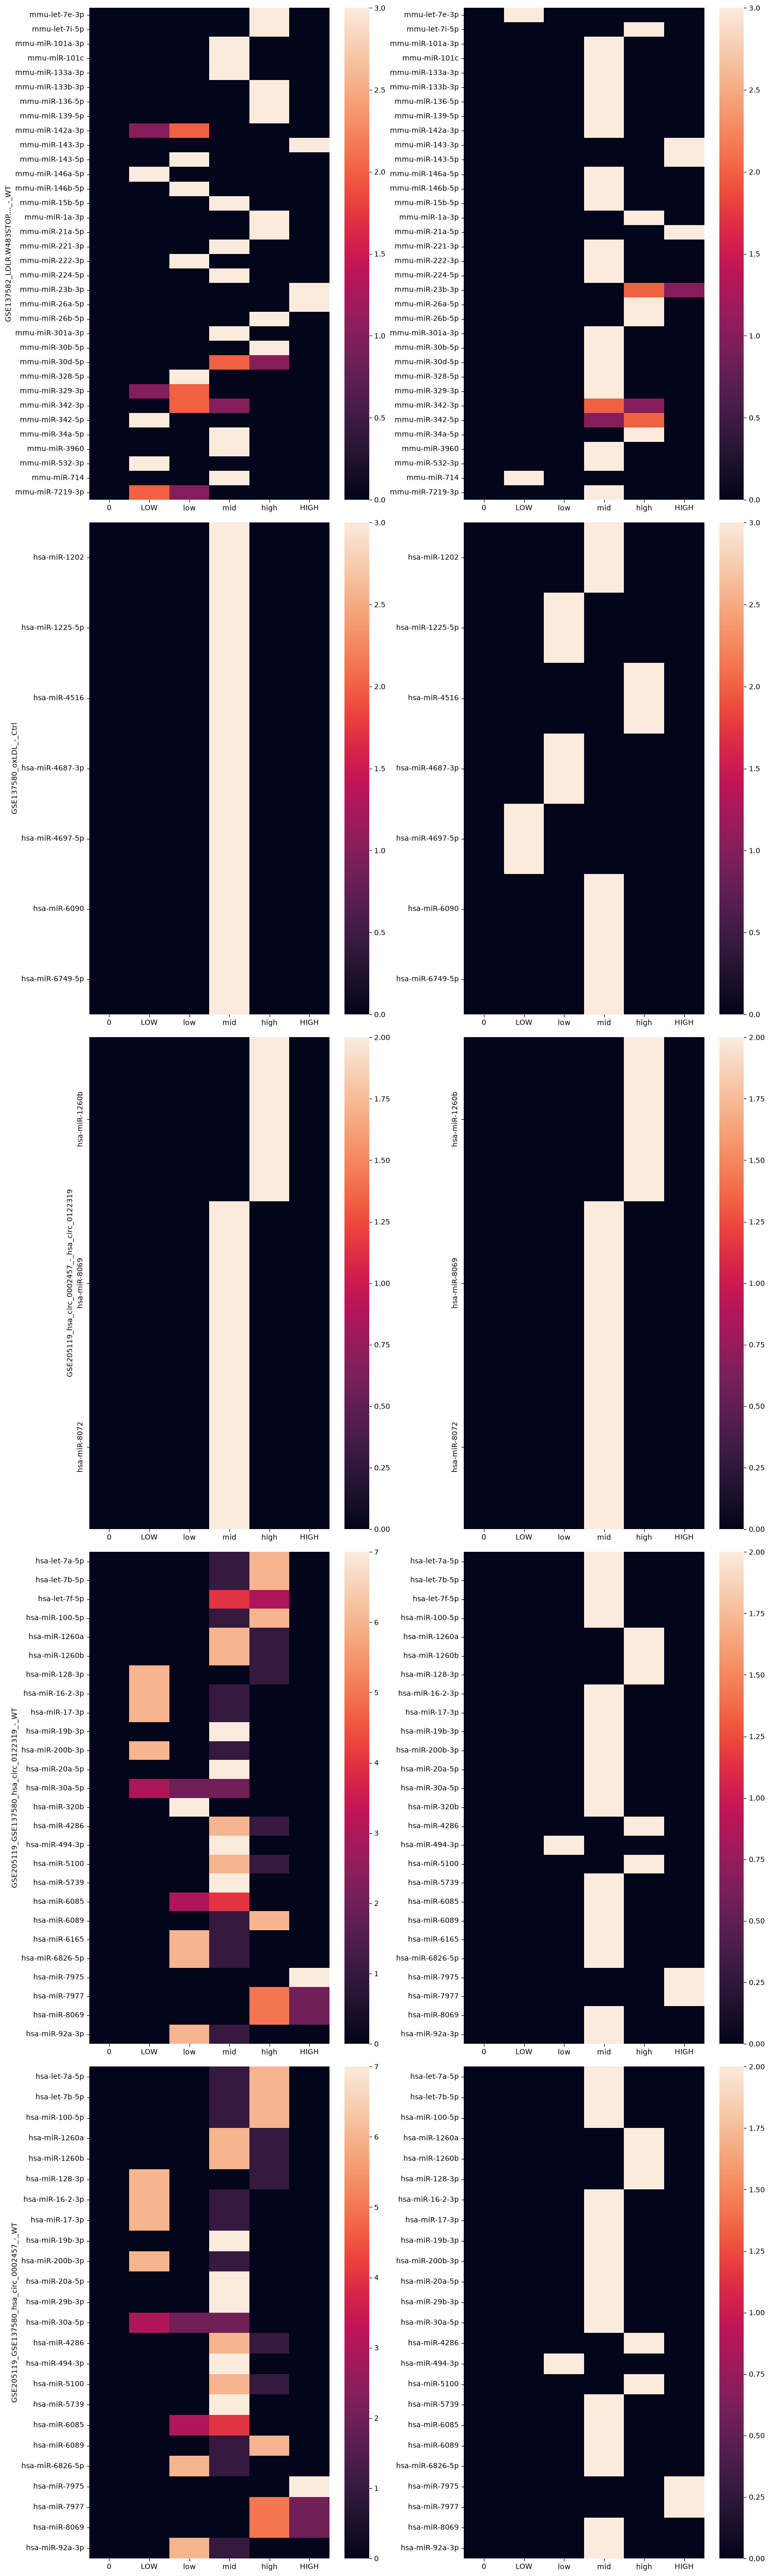

In [ ]:
fig, axes = plt.subplots(len(results.keys()), 2, figsize=(15, 10*len(results.keys())))
for i, key in enumerate(results.keys()):
    axes[i, 0] = sns.heatmap(results[key]["ref"], ax=axes[i,0])
    axes[i, 1] = sns.heatmap(results[key]["test"], ax=axes[i,1])
    axes[i,0].set_ylabel(key)
plt.tight_layout()

# Data Loading mRMA

In [13]:
fuzz_res_dir = Path(r"C:\Users\jonas\OneDrive\Desktop\Semester_4_Bio\Masterpraktikum\Data\fuzzy_res_mRNA")

In [14]:
with open(r"C:\Users\jonas\OneDrive\Desktop\Semester_4_Bio\Masterpraktikum\relevant_views_mRNA.json", "r") as f:
    data = json.load(f)

In [15]:
cond_matches = pd.read_csv(r"C:\\Users\\jonas\\OneDrive\\Desktop\\Semester_4_Bio\\Masterpraktikum\\condition_matches_mRNA.csv", index_col=0)
cond_matches.head()

,accession,test,reference,test_coef,reference_coef,groupcol,safe_label
1,GSE101126,shADK,shCtrl,shADK,shCtrl,KO,shADK_-_shCtrl
2,GSE13139,LOX1_OE,GFP_OE,LOX1_OE,GFP_OE,KO,LOX1_OE_-_GFP_OE
3,GSE137578,oxLDL,Ctrl,oxLDL,Ctrl,medication,oxLDL_-_Ctrl
4,GSE137581,LDLR(W483STOP)+/+,WT,LDLR.W483STOP....,WT,KO,LDLR.W483STOP...._-_WT
5,GSE15062,LTBR,Ctrl,LTBR,Ctrl,medication,LTBR_-_Ctrl


In [16]:
meta = pd.read_excel(r"C:\Users\jonas\OneDrive\Desktop\Semester_4_Bio\Masterpraktikum\metadata_all_samples_new.xlsx")
meta['CAD'] = meta['CAD'].astype(str)
meta['CAD'] = meta['CAD'].map({"1.0": "TRUE", "0.0": "FALSE"})
meta['CVD'] = meta['CVD'].astype(str)
meta['CVD'] = meta['CVD'].map({"1.0": "TRUE", "0.0": "FALSE"})
meta['diabetis'] = meta['diabetis'].astype(str)
meta['diabetis'] = meta['diabetis'].map({"1.0": "TRUE", "0.0": "FALSE"})
meta['Hutchinson-Gilford'] = meta['Hutchinson-Gilford'].astype(str)
meta['Hutchinson-Gilford'] = meta['Hutchinson-Gilford'].map({"1.0": "TRUE", "0.0": "FALSE"})
meta['symptomatic_atherosclerosis'] = meta['symptomatic_atherosclerosis'].astype(str)
meta['symptomatic_atherosclerosis'] = meta['symptomatic_atherosclerosis'].map({"1.0": "TRUE", "0.0": "FALSE"})
meta.shape

(1607, 21)

# Process data into useful combinations

In [17]:
mRNA_data = pd.DataFrame(data).T
mRNA_data['n_overlap'] = [len(x) for x in mRNA_data['Overlap']]
mRNA_data['accession'] = [x.split("_")[0] for x in mRNA_data.index]
mRNA_data['contrast'] = ["_".join(x.split("_")[1:-1]) for x in mRNA_data.index]
mRNA_data_comb = mRNA_data.merge(cond_matches, left_on=["accession", "contrast"], right_on=["accession", "safe_label"])
mRNA_data_comb.index = mRNA_data_comb["accession"] + "_" + mRNA_data_comb["safe_label"]
mRNA_data_comb.head()

,padj,logfc,Overlap,n_overlap,accession,contrast,test,reference,test_coef,reference_coef,groupcol,safe_label
GSE101126_shADK_-_shCtrl,"[MIR4481, KIF20A, MKI67, TTK, HSPA1A, PLK1, AU...","[MIR4481, KIF20A, MKI67, TTK, HSPA1A, PLK1, AU...","[GDF3, LRRC57, CDKN2C, FAM136A, USP13, PLEKHM2...",4716,GSE101126,shADK_-_shCtrl,shADK,shCtrl,shADK,shCtrl,KO,shADK_-_shCtrl
GSE13139_LOX1_OE_-_GFP_OE,"[RAP1A, DTX2P1-UPK3BP1-PMS2P11, LOC105379426, ...","[RAP1A, DTX2P1-UPK3BP1-PMS2P11, LOC105379426, ...","[DCTPP1, LRRC57, PPP4R1L, USP13, SERAC1, KIF9,...",6233,GSE13139,LOX1_OE_-_GFP_OE,LOX1_OE,GFP_OE,LOX1_OE,GFP_OE,KO,LOX1_OE_-_GFP_OE
GSE137578_oxLDL_-_Ctrl,"[G0S2, BIRC5, SPC25, KIF20A, UBE2C, IRS2, TLR2...","[G0S2, BIRC5, SPC25, KIF20A, UBE2C, IRS2, TLR2...","[DCTPP1, LRRC57, TLR2, USP13, CARD16, lnc-DYDC...",9394,GSE137578,oxLDL_-_Ctrl,oxLDL,Ctrl,oxLDL,Ctrl,medication,oxLDL_-_Ctrl
GSE137581_LDLR.W483STOP...._-_WT,"[Spp1, Htr2b, Cdk18, Lilrb4, Timp1, Bex1, Clec...","[Spp1, Htr2b, Cdk18, Lilrb4, Timp1, Bex1, Clec...","[Ehbp1, 4930520O04Rik, Gm32566, Ptpn7, chr1:13...",8495,GSE137581,LDLR.W483STOP...._-_WT,LDLR(W483STOP)+/+,WT,LDLR.W483STOP....,WT,KO,LDLR.W483STOP...._-_WT
GSE15062_LTBR_-_Ctrl,"[Nfkbia, Map3k14, Traf3, Sox4, Junb, Relb, Cas...","[Nfkbia, Map3k14, Traf3, Sox4, Junb, Relb, Cas...","[Casp4, Relb, Nfkb2, Junb, Traf3, Map3k14, Sox...",9,GSE15062,LTBR_-_Ctrl,LTBR,Ctrl,LTBR,Ctrl,medication,LTBR_-_Ctrl


# test data loading for expression validation

In [18]:
def check_expression(metadata, gse, condition, target_genes, condition_col=True):
    meta_sub = metadata[(metadata['accession'] == gse) & (metadata[condition_col]==condition)]
    datasets = pd.DataFrame()
    for file in (fuzz_res_dir / f"{gse}_norm_data_E_sample" / "fuzzy_values").glob("*"):
        if any([str(x) in file.name for x in meta_sub['sample']]):
            tmp = pd.read_csv(file, sep="\t", index_col=0)
            tmp = tmp.loc[target_genes, :]
            datasets = pd.concat([datasets, tmp])
    maxes = datasets[["0", "LOW", "low", "mid", "high", "HIGH"]].max(axis=1)
    datasets_bool = datasets[["0", "LOW", "low", "mid", "high", "HIGH"]].copy()
    for col in datasets_bool.columns:
        datasets_bool[col] = (datasets_bool[col] == maxes)
    return datasets_bool.groupby(level=0).sum()

In [19]:
results = {}
human_mRNA_ds_counter = {"ECs": Counter(), "SMCs": Counter(), "plaque": Counter(), "tissue": Counter()}
mouse_mRNA_ds_counter = {"ECs": Counter(), "SMCs": Counter(), "plaque": Counter(), "tissue": Counter()}
human_mRNA_ds = {"ECs": defaultdict(list), "SMCs": defaultdict(list), "plaque": defaultdict(list), "tissue": defaultdict(list)}
mouse_mRNA_ds = {"ECs": defaultdict(list), "SMCs": defaultdict(list), "plaque": defaultdict(list), "tissue": defaultdict(list)}
human_mRNA_ds_ext = {"ECs": defaultdict(list), "SMCs": defaultdict(list), "plaque": defaultdict(list), "tissue": defaultdict(list)}
mouse_mRNA_ds_ext = {"ECs": defaultdict(list), "SMCs": defaultdict(list), "plaque": defaultdict(list), "tissue": defaultdict(list)}
for i, row in mRNA_data_comb.iterrows():
    targets = row["Overlap"]
    clean_targets = [x for x in targets if not x.startswith("A_")]
    test_df = check_expression(metadata = meta, gse = row['accession'], condition = row['test'], target_genes = clean_targets, condition_col=row['groupcol'])
    ref_df = check_expression(metadata = meta, gse = row['accession'], condition = row['reference'], target_genes = clean_targets, condition_col = row['groupcol'])
    results[i] = {
        "test": test_df,
        "ref": ref_df
        }
    
    threshold_test = np.ceil(test_df.sum(axis=1)[0])
    threshold_ref = np.ceil(ref_df.sum(axis=1)[0])

    test_bool = test_df[["mid", "high", "HIGH"]].sum(axis=1) >= threshold_test
    ref_bool = ref_df[["mid", "high", "HIGH"]].sum(axis=1) >= threshold_ref
    celltype = meta.loc[meta['accession']==row['accession'], 'cell_type'].iloc[0]
    if celltype in ["ECs", "SMCs", "tissue", "plaque"]:
        for mRNA in clean_targets:
            if test_bool[mRNA] or ref_bool[mRNA]:
                if meta.loc[meta['accession']==row['accession'], 'species'].iloc[0] == "Human":
                    human_mRNA_ds_ext[celltype][mRNA].append((row['accession'], row['safe_label']))
                    human_mRNA_ds[celltype][mRNA].append(row['accession'])
                    human_mRNA_ds_counter[celltype].update([mRNA])
                else:
                    human_mRNA_ds_ext[celltype][mRNA].append((row['accession'], row['safe_label']))
                    mouse_mRNA_ds[celltype][mRNA].append(row['accession'])
                    mouse_mRNA_ds_counter[celltype].update([mRNA])
    else:
        print(f"skipping: {celltype} not interesting ({row['accession']})")
human_mRNA_ds_counter

skipping: HAECT not interesting (GSE13139)
skipping: blood not interesting (GSE46097)
skipping: blood not interesting (GSE46097)


{'ECs': Counter({'PBK': 8,
          'HMMR': 8,
          'CDR2L': 8,
          'CHMP1B': 8,
          'KIF20A': 8,
          'CEP55': 8,
          'CCNB2': 8,
          'MYH10': 8,
          'P3H4': 8,
          'PRC1': 8,
          'DDX21': 8,
          'CCNA2': 8,
          'TOP2A': 8,
          'CEBPB': 8,
          'ASPM': 8,
          'SLC44A2': 8,
          'PLEKHB2': 8,
          'CELF1': 8,
          'KIF4A': 8,
          'FKBP4': 8,
          'CDKN3': 8,
          'TYMS': 8,
          'PPP1R10': 7,
          'MCM2': 7,
          'PSME4': 7,
          'CCL2': 7,
          'JUN': 7,
          'KLHL21': 7,
          'ZFYVE26': 7,
          'DNAJB1': 7,
          'HMOX1': 7,
          'MANF': 7,
          'ARG2': 7,
          'PXK': 7,
          'HSPA1A': 7,
          'UBE2H': 7,
          'GINS2': 7,
          'PHGDH': 7,
          'XRCC1': 7,
          'RRS1': 7,
          'NRIP1': 7,
          'NIF3L1': 7,
          'LOX': 7,
          'MAFF': 7,
          'UBR4': 7,
         

In [20]:
with open(r'C:\Users\jonas\OneDrive\Desktop\Semester_4_Bio\Masterpraktikum\mRNA_view_occurences_human.json', 'w') as fp:
    json.dump(human_mRNA_ds_ext, fp)
with open(r'C:\Users\jonas\OneDrive\Desktop\Semester_4_Bio\Masterpraktikum\mRNA_view_occurences_mouse.json', 'w') as fp:
    json.dump(mouse_mRNA_ds_ext, fp)

# mRNA: View analysis

In [ ]:
tmp_mouse = pd.DataFrame(mouse_mRNA_ds_counter)
tmp_mouse['gene'] = tmp_mouse.index
tmp_mouse

In [ ]:
tmp_human = pd.DataFrame(human_mRNA_ds_counter)
tmp_human['gene'] = tmp_human.index
tmp_human

,ECs,SMCs,plaque,tissue,gene
GDF3,4.0,NaN,NaN,NaN,GDF3
LRRC57,4.0,NaN,NaN,NaN,LRRC57
FAM136A,3.0,NaN,NaN,NaN,FAM136A
USP13,6.0,NaN,NaN,NaN,USP13
PLEKHM2,6.0,2.0,NaN,NaN,PLEKHM2
...,...,...,...,...,...
CCM2,NaN,1.0,NaN,NaN,CCM2
WFDC10B,NaN,1.0,NaN,NaN,WFDC10B
SFRP2,NaN,1.0,NaN,NaN,SFRP2
KRTAP6-2,NaN,1.0,NaN,NaN,KRTAP6-2


<Axes: xlabel='gene', ylabel='counts'>

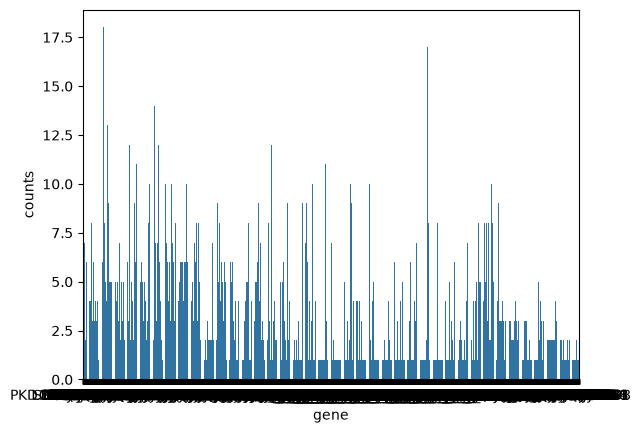

In [ ]:
sns.barplot(tmp_human, x="gene", y="counts")

<Axes: xlabel='ECs', ylabel='Count'>

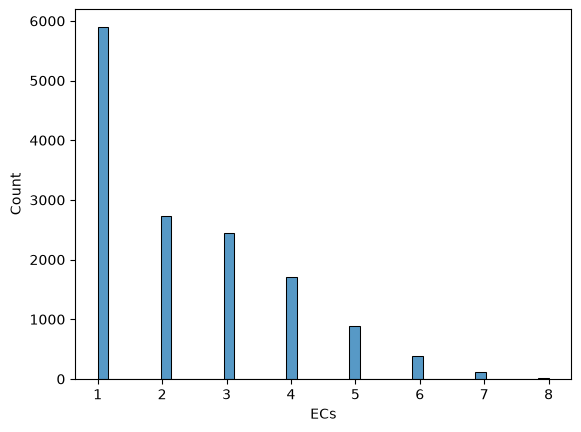

In [ ]:
sns.histplot(tmp_human, x="ECs")

<Axes: xlabel='SMCs', ylabel='Count'>

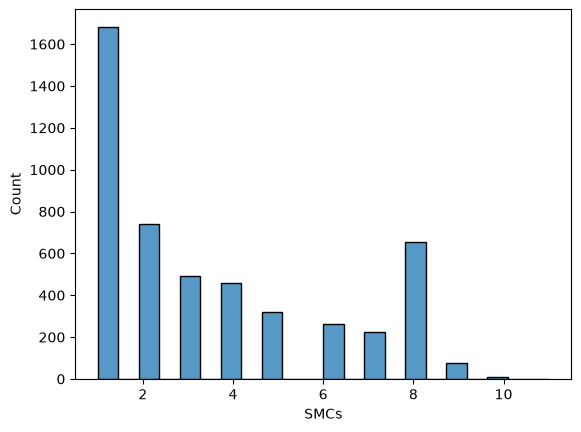

In [ ]:
sns.histplot(tmp_human, x="SMCs")

<Axes: xlabel='SMCs', ylabel='Count'>

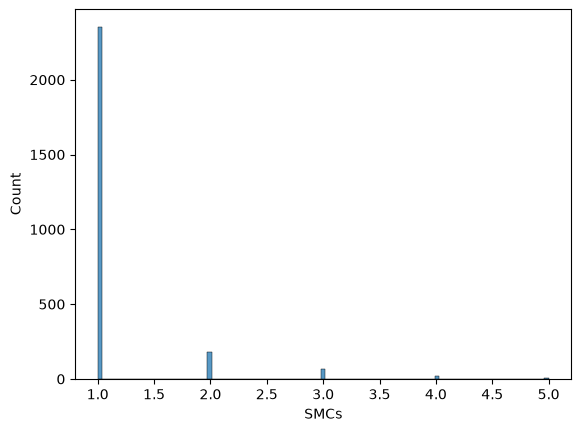

In [ ]:
sns.histplot(tmp_mouse, x="SMCs")

<Axes: xlabel='tissue', ylabel='Count'>

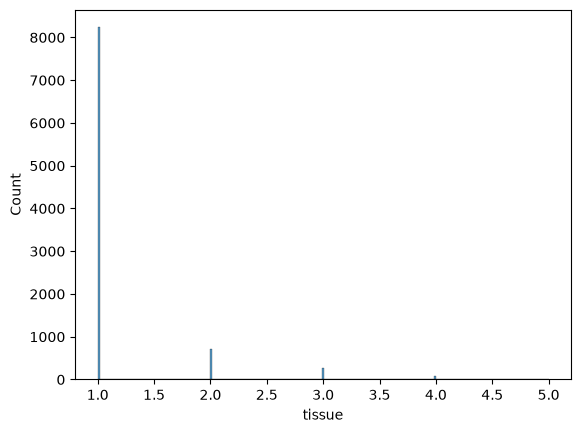

In [ ]:
sns.histplot(tmp_mouse, x="tissue")

<Axes: xlabel='gene', ylabel='counts'>

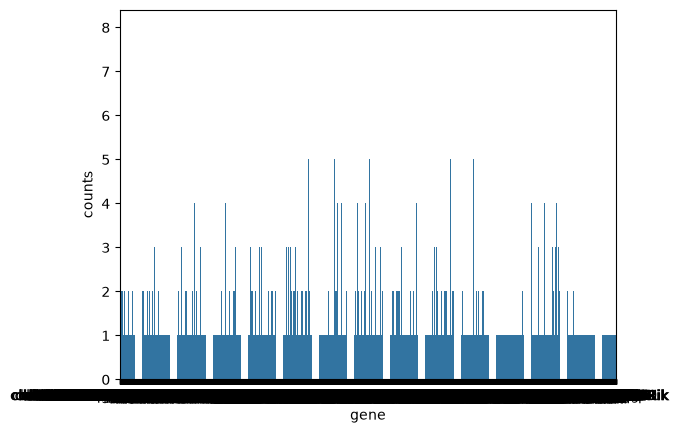

In [ ]:
sns.barplot(tmp_mouse, x="gene", y="counts")

In [ ]:
fig, axes = plt.subplots(len(results.keys()), 2, figsize=(15, 5*len(results.keys())))
for i, key in enumerate(results.keys()):
    axes[i, 0] = sns.heatmap(results[key]["ref"], ax=axes[i,0])
    axes[i, 1] = sns.heatmap(results[key]["test"], ax=axes[i,1])
    axes[i,0].set_ylabel(key)
plt.tight_layout()
#plt.savefig(r"C:\Users\jonas\OneDrive\Desktop\Semester_4_Bio\Masterpraktikum\miRNA_expression.svg")
#plt.savefig(r"C:\Users\jonas\OneDrive\Desktop\Semester_4_Bio\Masterpraktikum\miRNA_expression.png")

# Mouse: miRNA target analysis

In [57]:
miRNA_targets_mouse = pd.read_csv(r"C:\Users\jonas\OneDrive\Desktop\Semester_4_Bio\Masterpraktikum\miRNA_targets_mouse.csv")
miRNA_targets_mouse

,miRNA,gene,evidence,source
0,mmu-miR-136-5p,Rtl1,validated,mirecords
1,mmu-miR-23b-3p,Hes1,validated,mirecords
2,mmu-miR-23b-3p,Mdh2,validated,mirecords
3,mmu-miR-23b-3p,Lmnb1,validated,mirecords
4,mmu-miR-23b-3p,Smad3,validated,mirecords
...,...,...,...,...
127469,mmu-let-7i-5p,Mtres1,predicted,diana_microt; elmmo; microcosm; miranda; mirdb...
127470,mmu-miR-34a-5p,Gm10401,predicted,diana_microt; elmmo; microcosm; miranda; mirdb...
127471,mmu-miR-133b-3p,Rida,predicted,diana_microt; elmmo; microcosm; miranda; mirdb...
127472,mmu-let-7i-5p,Or1p1c,predicted,diana_microt; elmmo; microcosm; miranda; mirdb...


In [60]:
tmp = pd.DataFrame(mouse_mRNA_ds_counter['ECs'], index=["ECs"]).T
tmp['miRNA_target'] = [x in miRNA_targets_mouse[miRNA_targets_mouse['evidence']=="validated"]['gene'].tolist() for x in tmp.index]
tmp['gene'] = tmp.index
tmp[["ECs", "miRNA_target"]].sum()

ECs             2876
miRNA_target    2407
dtype: int64

In [61]:
len(miRNA_targets_mouse['gene'].unique())

17770

In [ ]:
tmp = pd.DataFrame(mouse_mRNA_ds_counter['ECs'], index=["ECs"]).T
tmp['miRNA_target'] = [x in miRNA_targets_mouse['gene'].tolist() for x in tmp.index]
tmp['gene'] = tmp.index
tmp[["ECs", "miRNA_target"]].sum()

,ECs,miRNA_target,gene
Baz1a,1,True,Baz1a
Tmt1a3,1,False,Tmt1a3
H3c3,1,True,H3c3
Mr1,1,True,Mr1
Tspan2,1,True,Tspan2
...,...,...,...
Rab40b,1,True,Rab40b
Slc1a4,1,True,Slc1a4
Parvb,1,True,Parvb
Insr,1,True,Insr


In [59]:
tmp[["ECs", "miRNA_target"]].sum()

ECs             2876
miRNA_target    2531
dtype: int64

<Axes: xlabel='gene', ylabel='ECs'>

c:\Users\jonas\miniforge3\envs\scRNAseq\Lib\site-packages\IPython\core\events.py:100: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
c:\Users\jonas\miniforge3\envs\scRNAseq\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


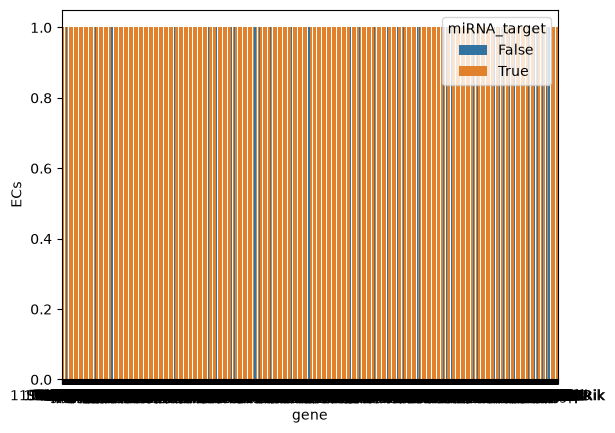

In [30]:
sns.barplot(tmp, x="gene", y="ECs", hue="miRNA_target")

# Human: miRNA target analysis

In [72]:
miRNA_targets_human = pd.read_csv(r"C:\Users\jonas\OneDrive\Desktop\Semester_4_Bio\Masterpraktikum\miRNA_targets_human.csv")
miRNA_targets_human

,miRNA,gene,evidence,source
0,hsa-let-7b-5p,LIN28,validated,mirecords
1,hsa-let-7b-5p,CCND1,validated,mirecords
2,hsa-let-7b-5p,CDC25A,validated,mirecords
3,hsa-let-7b-5p,BCL7A,validated,mirecords
4,hsa-let-7b-5p,HMGA2,validated,mirecords
...,...,...,...,...
148740,hsa-let-7a-5p,MTRES1,predicted,diana_microt; elmmo; microcosm; miranda; mirdb...
148741,hsa-let-7f-5p,MTRES1,predicted,diana_microt; elmmo; microcosm; miranda; mirdb...
148742,hsa-let-7b-5p,MTRES1,predicted,diana_microt; elmmo; microcosm; miranda; mirdb...
148743,hsa-miR-29b-3p,STMP1,predicted,diana_microt; elmmo; microcosm; miranda; mirdb...


In [73]:
sub_miRNA_targets_human = miRNA_targets_human[miRNA_targets_human['miRNA'].isin(["hsa-miR-1260b", "hsa-miR-8069"])]
sub_miRNA_targets_human

,miRNA,gene,evidence,source
8127,hsa-miR-1260b,E2F3,validated,mirtarbase
8128,hsa-miR-1260b,G3BP1,validated,mirtarbase
8129,hsa-miR-1260b,DHCR24,validated,mirtarbase
8130,hsa-miR-1260b,POLR3G,validated,mirtarbase
8131,hsa-miR-1260b,CDKN1A,validated,mirtarbase
...,...,...,...,...
144662,hsa-miR-1260b,ETV5,predicted,diana_microt; elmmo; microcosm; miranda; mirdb...
144663,hsa-miR-1260b,LAMC2,predicted,diana_microt; elmmo; microcosm; miranda; mirdb...
144664,hsa-miR-1260b,DCAF11,predicted,diana_microt; elmmo; microcosm; miranda; mirdb...
144676,hsa-miR-1260b,STAC2,predicted,diana_microt; elmmo; microcosm; miranda; mirdb...


In [108]:
len(list(sub_miRNA_targets_human[sub_miRNA_targets_human['evidence']=="validated"]['gene'].unique()))

460

In [93]:
tmp = pd.DataFrame(human_mRNA_ds_counter['ECs'], index=["ECs"]).T
tmp['miRNA_target'] = [x in sub_miRNA_targets_human['gene'].tolist() for x in tmp.index]
tmp['gene'] = tmp.index
tmp[["ECs", "miRNA_target"]].sum()

ECs             33274
miRNA_target      741
dtype: int64

In [89]:
tmp = pd.DataFrame(human_mRNA_ds_counter['ECs'], index=["ECs"]).T
tmp['miRNA_target'] = [x in sub_miRNA_targets_human[sub_miRNA_targets_human['evidence']=="validated"]['gene'].tolist() for x in tmp.index]
tmp['gene'] = tmp.index
tmp[["ECs", "miRNA_target"]].sum()

ECs             33274
miRNA_target      375
dtype: int64

In [80]:
x = Counter()
for _, row in tmp[tmp['ECs']>0].iterrows():
    if row['miRNA_target']:
        x.update(set(human_mRNA_ds['ECs'][row['gene']]))
x

Counter({'GSE137578': 230,
         'GSE72633': 224,
         'GSE101126': 131,
         'GSE20739': 129,
         'GSE26295': 88,
         'GSE20060': 76,
         'GSE72180': 5})

In [88]:
x = Counter()
for _, row in tmp[tmp['ECs']>0].iterrows():
    if row['miRNA_target']:
        x.update(set(human_mRNA_ds_ext['ECs'][row['gene']]))
x

Counter({('GSE137578', 'oxLDL_-_Ctrl'): 230,
         ('GSE72633', 'oxPAPC_-_siCtrl'): 159,
         ('GSE72633', 'oxPAPC_-_siNotch1'): 156,
         ('GSE101126', 'shADK_-_shCtrl'): 131,
         ('GSE20739',
          'stable.laminar.shear.stress_-_oscillatory.wall.shear.stress'): 129,
         ('GSE72633', 'siNotch1_-_siCtrl'): 96,
         ('GSE26295', 'X3OC12Hsl_-_medium'): 88,
         ('GSE20060', 'oxPAPC_-_Ctrl'): 76,
         ('GSE72180', 'WT_-_KRR.'): 5})

In [81]:
x = Counter()
for _, row in tmp[tmp['ECs']>0].iterrows():
    if row['miRNA_target']:
        x.update(human_mRNA_ds['ECs'][row['gene']])
x

Counter({'GSE72633': 411,
         'GSE137578': 230,
         'GSE101126': 131,
         'GSE20739': 129,
         'GSE26295': 88,
         'GSE20060': 76,
         'GSE72180': 5})